# Early Detection of Event-Associated Public Attention Shifts in Olympic Gymnastics Discourse

**COMP8851 Major Project 

Scope: Olympic gymnastics discourse

The token `men's` appears in 2.9% of the seed set. An event-specific subset for the
men's final is therefore on the order of 50–70 documents after deduplication. With
`min_topic_size = 25` this admits at most two topics, and BERTopic's UMAP step is
unreliable at that scale. The men's final is not analysable in this corpus.

Following the second option in the supervisor feedback, the scope is broadened to
**Olympic gymnastics discourse during the Tokyo 2020 Games**, and the research
questions will be revised accordingly.

In [ ]:
from collections import Counter

# Start from terms that are unarguably gymnastics-specific
seed_terms = ["gymnast", "gymnastics", "all-around", "allaround"]
seed_set = corpus[corpus["clean"].apply(lambda t: has_exact_word(t, seed_terms))]

print(f"Seed set: {len(seed_set):,} documents from {len(seed_terms)} seed terms")

# What vocabulary co-occurs with those seeds?
words = Counter()
for text in seed_set["clean"]:
    words.update(w for w in text.split() if len(w) > 3)

frequent = pd.DataFrame(words.most_common(50), columns=["Term", "Frequency"])
frequent["% of Seed Set"] = (100 * frequent["Frequency"] / len(seed_set)).round(1)

display(
    frequent.style
    .format({"Frequency": "{:,.0f}", "% of Seed Set": "{:.1f}%"})
    .set_properties(subset=["Term"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index")
)

Seed set: 3,638 documents from 4 seed terms


Term,Frequency,% of Seed Set
gymnastics,"2,932",80.6%
olympics,"2,266",62.3%
gymnast,808,22.2%
simone,676,18.6%
biles,666,18.3%
team,610,16.8%
tokyo,565,15.5%
from,400,11.0%
final,390,10.7%
around,349,9.6%


### 1. Environment Setup

The analysis environment is configured with the required Python libraries and their specified versions to ensure reproducibility.

In [166]:
import os
import re                                   
import time                                 
import hashlib 
import sys 
import gc                                                
from datetime import timedelta               
from pathlib import Path                    
from importlib.metadata import version    
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from pytrends.request import TrendReq
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from sklearn.metrics import adjusted_rand_score
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



os.environ["HF_HUB_OFFLINE"] = "1" 

seed = 8851
np.random.seed(seed)

print("python               :", sys.version.split()[0])
print("pandas               :", version("pandas"))
print("numpy                :", version("numpy"))
print("scikit-learn         :", version("scikit-learn"))
print("bertopic             :", version("bertopic"))
print("umap-learn           :", version("umap-learn"))
print("hdbscan              :", version("hdbscan"))
print("sentence-transformers:", version("sentence-transformers"))
print("pytrends             :", version("pytrends"))
print("random seed          :", seed)

python               : 3.11.9
pandas               : 3.0.5
numpy                : 2.4.6
scikit-learn         : 1.9.0
bertopic             : 0.17.4
umap-learn           : 0.5.12
hdbscan              : 0.8.44
sentence-transformers: 6.0.0
pytrends             : 4.9.2
random seed          : 8851


### 2. Experimental Settings

The analysis settings define the CSV file path, word-count limits (4–50 words), and sample size used for the analysis.

In [167]:
df = "Olympics_Tokyo_tweets.csv" 

min_words = 4             
scope_sample_size = 250000 
min_topic_size = 25
min_documents_per_day = 30      

### 3. Dataset Loading and Timestamp Processing

The dataset author does not provide explicit information about the timezone of the timestamps stored in the Kaggle CSV file. However, the dataset description states that the tweets were collected using the Twitter API through Tweepy. Twitter API tweet timestamps are represented in UTC; therefore, although the CSV `date` field is stored as a timezone-naive `YYYY-MM-DD HH:MM:SS` string, the timestamps are interpreted as UTC based on the Twitter API timestamp convention. This interpretation is not based on timezone metadata retained in the Kaggle CSV, but on the documented timestamp convention of the API through which the tweets were collected.

For temporal analysis, the timestamps are explicitly parsed as UTC and then converted to the named `Asia/Tokyo` timezone. The original UTC representation and the converted Tokyo-local timestamp are both retained, allowing the timezone conversion to be inspected and verified rather than applying a fixed nine-hour offset manually.


In [168]:
tweets = pd.read_csv(df, low_memory=False) 

tweets["ts_utc"] = pd.to_datetime(tweets["date"], errors="coerce", utc=True)  # parse as UTC
tweets = tweets.dropna(subset=["ts_utc"])                    # drop unparseable timestamps
tweets["ts_jst"] = tweets["ts_utc"].dt.tz_convert("Asia/Tokyo")  # convert by named zone

tweets["day"] = tweets["ts_jst"].dt.date     # analysis date comes from JST
tweets["hour"] = tweets["ts_jst"].dt.hour    # used to report collection coverage

observed_days = sorted(tweets["day"].unique())
full_range = pd.date_range(
    min(observed_days),
    max(observed_days),
    freq="D").date
missing_days = [
    d for d in full_range
    if d not in observed_days]

daily = pd.DataFrame({"day": full_range})
daily["tweets"] = (
    daily["day"]
    .map(tweets.groupby("day").size()))
daily["hours"] = (
    daily["day"]
    .map(tweets.groupby("day")["hour"].nunique()))
daily["share"] = (
    daily["tweets"] / daily["tweets"].sum() * 100).round(1)
daily["status"] = daily["tweets"].notna().map({
    True: "Collected",
    False: "Not Collected"})

print(f"Total tweets   : {len(tweets):,}")
print(
    f"Calendar range : {min(observed_days)} to {max(observed_days)}"
    f" ({len(full_range)} days)")
print(f"Collected      : {len(observed_days)} days")
print(
    f"Not collected  : {len(missing_days)} days -> "
    f"{[str(d) for d in missing_days]}")

daily.columns = [
    "Date",
    "Tweet Count",
    "Hours Collected",
    "Tweet Share (%)",
    "Collection Status"]

display(daily) 

Total tweets   : 312,791
Calendar range : 2021-07-25 to 2021-08-08 (15 days)
Collected      : 9 days
Not collected  : 6 days -> ['2021-08-02', '2021-08-03', '2021-08-04', '2021-08-05', '2021-08-06', '2021-08-07']


,Date,Tweet Count,Hours Collected,Tweet Share (%),Collection Status
0,2021-07-25,500.0,3.0,0.2,Collected
1,2021-07-26,47000.0,12.0,15.0,Collected
2,2021-07-27,62499.0,16.0,20.0,Collected
3,2021-07-28,32499.0,7.0,10.4,Collected
4,2021-07-29,30000.0,8.0,9.6,Collected
5,2021-07-30,32497.0,9.0,10.4,Collected
6,2021-07-31,51415.0,14.0,16.4,Collected
7,2021-08-01,33885.0,9.0,10.8,Collected
8,2021-08-02,NaN,NaN,NaN,Not Collected
9,2021-08-03,NaN,NaN,NaN,Not Collected


### 4. Data Cleaning and Deduplication

Text normalisation is performed before duplicate removal so that tweets differing only in punctuation or letter casing are identified as duplicates.

**Language rule.** This study is **English-only**. The cleaning step retains only the
characters `A–Z`, apostrophe, and space, which encodes that assumption.

The rule is approximate in two directions and both are reported rather than corrected.
Non-Latin-script tweets are not removed directly; they are reduced to near-empty
strings and then dropped by the four-token minimum. Romanised non-English tweets
survive cleaning and may remain in the corpus. No language-identification step is
applied at this stage.

In [169]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # URLs are identifiers, not vocabulary
    text = re.sub(r"@\w+", " ", text)               # mentions denote accounts, not subjects
    text = text.replace("#", "")                    # retain the token, discard the marker
    text = re.sub(r"[^A-Za-z' ]+", " ", text)       # encodes the English-only assumption
    return re.sub(r"\s+", " ", text).strip().lower()

steps = []
corpus = tweets.copy()
steps.append(["Timestamped records", len(corpus),
              "Records retained after timestamp parsing"])
corpus = corpus.drop_duplicates(subset="id")
steps.append(["Duplicate identifiers removed", len(corpus),
              "Overlapping collection runs introduce repeated records"])
corpus = corpus[corpus["text"].notna()]
steps.append(["Empty text removed", len(corpus),
              "Records without content cannot be assigned to a topic"])
corpus = corpus[~corpus["text"].astype(str).str.startswith("RT @")]
steps.append(["Retweets removed", len(corpus),
              "Amplification of a message is not independent discussion"])
corpus["clean"] = corpus["text"].apply(clean_text)
steps.append(["Text normalised", len(corpus),
              "Applied prior to deduplication so that near-duplicates are detected"])
corpus = corpus.drop_duplicates(subset="clean")
steps.append(["Duplicate text removed", len(corpus),
              "Records identical once punctuation and URLs are stripped"])
corpus = corpus[corpus["clean"].str.split().str.len() >= min_words]
steps.append([f"Records under {min_words} tokens removed", len(corpus),
              "Insufficient tokens for reliable placement during clustering"])

corpus = corpus.reset_index(drop=True)

cleaning = pd.DataFrame(steps, columns=["Operations", "Records Retained", "Rationale"])
cleaning["Removed"] = (cleaning["Records Retained"].shift(1)
                       - cleaning["Records Retained"])
cleaning["% of Initial"] = (cleaning["Records Retained"]
                            / cleaning["Records Retained"].iloc[0] * 100).round(1)
cleaning = cleaning[["Operations", "Records Retained", "Removed",
                     "% of Initial", "Rationale"]]

display(
    cleaning.style
    .format({"Removed": "{:,.0f}",
             "Records Retained": "{:,.0f}",
             "% of Initial": "{:.1f}%"}, na_rep="—")
    .set_properties(subset=["Operations", "Rationale"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

print(f"Analysis corpus: {len(corpus):,} records "
      f"({len(corpus)/len(tweets)*100:.1f}% of timestamped records), "
      f"drawn from {corpus['user_screen_name'].nunique():,} accounts.")

,Operations,Records Retained,Removed,% of Initial,Rationale
0,Timestamped records,"312,791",—,100.0%,Records retained after timestamp parsing
1,Duplicate identifiers removed,"307,199","5,592",98.2%,Overlapping collection runs introduce repeated records
2,Empty text removed,"307,199",0,98.2%,Records without content cannot be assigned to a topic
3,Retweets removed,"307,199",0,98.2%,Amplification of a message is not independent discussion
4,Text normalised,"307,199",0,98.2%,Applied prior to deduplication so that near-duplicates are detected
5,Duplicate text removed,"267,853","39,346",85.6%,Records identical once punctuation and URLs are stripped
6,Records under 4 tokens removed,"261,467","6,386",83.6%,Insufficient tokens for reliable placement during clustering


Analysis corpus: 261,467 records (83.6% of timestamped records), drawn from 175,488 accounts.


## 5. Scope test on the whole corpus (Baseline 0)

Topic discovery with no gymnastics filter, to establish what the corpus contains
before narrowing. The gymnastics figure is a proportion **of this sample**.

In [170]:
def has_exact_word(text, words):
    """Match whole words only.

    \\b marks a word boundary. It is needed at BOTH ends: with only an opening
    boundary, 'cost' would also match 'costa' and 'app' would match 'apparently'.
    """
    return any(re.search(r"\b" + re.escape(w) + r"\b", text) for w in words)

In [171]:
scope_sample = corpus.sample(min(scope_sample_size, len(corpus)),
                             random_state=seed).reset_index(drop=True)

embedder = SentenceTransformer("all-MiniLM-L6-v2")   # turns tweets into meaning vectors

scope_model = BERTopic(embedding_model=embedder, min_topic_size=120, verbose=False)
scope_labels, _ = scope_model.fit_transform(scope_sample["clean"].tolist())
scope_labels = np.array(scope_labels)        # fit_transform returns a list

scope_words = {t: ", ".join(w for w, _ in scope_model.get_topic(t)[:8])
               for t in scope_model.get_topic_info()["Topic"] if t != -1}  # -1 is noise

scope_sizes = pd.Series(scope_labels).value_counts()

rows = []
for t in scope_sizes.index[:25]:
    if t == -1:
        continue
    rows.append({
        "Topic": t,
        "Documents": int(scope_sizes[t]),
        "% of Sample": round(100 * scope_sizes[t] / len(scope_sample), 2),
        "Representative Terms": scope_words[t],
    })

scope_table = pd.DataFrame(rows)

print(f"Sample: {len(scope_sample):,} documents "
      f"({len(scope_sample)/len(corpus)*100:.0f}% of the cleaned corpus)")
print(f"Topics identified: {len(scope_words)}")
print(f"Documents assigned to the outlier topic: "
      f"{(scope_labels == -1).mean()*100:.1f}%")
display(
    scope_table.style
    .format({"Documents": "{:,.0f}", "% of Sample": "{:.2f}%"})
    .set_properties(subset=["Representative Terms"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index")
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sample: 250,000 documents (96% of the cleaned corpus)
Topics identified: 286
Documents assigned to the outlier topic: 40.1%


Topic,Documents,% of Sample,Representative Terms
0,"9,320",3.73%,"tokyo, japan, tokyoolympics, japanese, day, games, olympicgames, medals"
1,"8,265",3.31%,"she, her, girl, was, woman, that, did, is"
2,"3,131",1.25%,"he, him, his, guy, was, man, at, be"
3,"2,942",1.18%,"biles, simone, mental, withdraws, health, around, gymnastics, competition"
4,"2,582",1.03%,"watching, watched, watch, haven, love, any, ve, am"
5,"2,511",1.00%,"nbc, coverage, app, channel, tv, cable, streaming, channels"
6,"2,197",0.88%,"this, give, started, happening, it, olympics, year, years"
7,"2,082",0.83%,"gold, silver, medal, medals, bronze, won, congratulations, count"
8,"1,869",0.75%,"song, songs, music, played, bts, blackpink, playing, theme"
9,"1,867",0.75%,"skateboarding, skating, skateboard, skateboarders, skate, skaters, skateboarder, street"


### 6. Constructing the gymnastics discourse set

The term list is derived from the data rather than specified in advance:

1. A small set of unarguable seed terms extracts an initial document set
2. Vocabulary co-occurring with those seeds is examined, and gymnastics-specific
   terms retained
3. Each term's document coverage is verified before use
4. The filter is applied (6.4) and its decisions reviewed

The filter contains competition vocabulary only. No consumer term appears in it,
so any consumer-related topic identified later is discovered from the data rather
than introduced by the selection.

In [172]:
seed_terms = ["gymnast", "gymnastics", "all around"]

seed_set = corpus[corpus["clean"].apply(lambda t: has_exact_word(t, seed_terms))]
print(f"Seed set: {len(seed_set):,} documents from {len(seed_terms)} seed terms")

words = Counter()
for text in seed_set["clean"]:
    words.update(w for w in text.split() if len(w) > 3)

frequent = pd.DataFrame(words.most_common(50), columns=["Term", "Frequency"])
frequent["% of Seed Set"] = (100 * frequent["Frequency"] / len(seed_set)).round(1)

Seed set: 4,116 documents from 3 seed terms


The term list is derived from the data rather than specified in advance. Three
seed terms that no reader could dispute — `gymnast`, `gymnastics` and
`all around` — extract an initial set of 4,116 documents. The vocabulary
occurring within that set then indicates which further terms are
gymnastics-specific, so the final filter follows from evidence rather than from
the researchers' prior knowledge.

`all around` refers to the event in which a gymnast competes on every apparatus,
the scores being summed to identify the best all-round competitor. It is
contested in both the men's and women's programmes and is included as general
gymnastics vocabulary, consistent with the broadened scope adopted in Section 1.
Only the spaced form is used: text normalisation removes hyphens, so the
hyphenated `all-around` cannot match any document in the cleaned corpus.

#### 6.1 Derive candidate terms from the data

In [173]:
blocks = 3
per_block = -(-len(frequent) // blocks)        

pieces = []
for i in range(blocks):
    piece = frequent.iloc[i * per_block:(i + 1) * per_block].reset_index(drop=True)
    # trailing spaces keep the names unique while displaying identically
    suffix = " " * i
    piece.columns = [f"Term{suffix}", f"Frequency{suffix}", f"% of Seed Set{suffix}"]
    pieces.append(piece)

wide = pd.concat(pieces, axis=1)

fmt, term_cols, block_starts = {}, [], []
for i in range(blocks):
    suffix = " " * i
    fmt[f"Frequency{suffix}"] = "{:,.0f}"
    fmt[f"% of Seed Set{suffix}"] = "{:.1f}%"
    term_cols.append(f"Term{suffix}")
    if i > 0:
        block_starts.append(f"Term{suffix}")     

styled = (
    wide.style
    .format(fmt, na_rep="")
    .set_properties(subset=term_cols, **{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left"),
                                     ("padding", "6px 14px")]},
        {"selector": "td", "props": [("padding", "6px 14px")]},
    ])
    .hide(axis="index"))

for col in block_starts:
    styled = styled.set_properties(
        subset=[col],
        **{"border-left": "2px solid #888", "padding-left": "26px"})

display(styled)

Term,Frequency,% of Seed Set,Term,Frequency,% of Seed Set,Term,Frequency,% of Seed Set
gymnastics,"2,932",71.2%,women,278,6.8%,time,129,3.1%
olympics,"2,502",60.8%,watching,265,6.4%,more,127,3.1%
biles,958,23.3%,watch,258,6.3%,men's,121,2.9%
simone,936,22.7%,withdraws,245,6.0%,simonebiles,118,2.9%
around,829,20.1%,with,221,5.4%,compete,115,2.8%
gymnast,808,19.6%,have,216,5.2%,live,113,2.7%
tokyo,716,17.4%,after,209,5.1%,only,111,2.7%
team,639,15.5%,mental,199,4.8%,when,110,2.7%
from,626,15.2%,just,197,4.8%,routine,107,2.6%
final,532,12.9%,will,197,4.8%,sports,105,2.6%


In [174]:
clear_terms = ["gymnast", "gymnastics", "gymnasts", "artistic gymnastics",
               "rhythmic gymnastics", "all around", "pommel", "uneven bars",
               "parallel bars", "high bar", "balance beam", "floor exercise",
               "floor routine", "still rings", "dismount", "tumbling",
               "simone biles", "sunisa lee", "hashimoto", "xiao ruoteng",
               "nikita nagornyy", "carlos yulo", "rebeca andrade"]

ambiguous_terms = ["vault", "bars", "beam", "ring", "rings", "floor"]

context_terms = ["gymnast", "gymnastics", "routine", "score",
                 "apparatus", "medal", "vaulting", "landing"]


def is_gymnastics(text):
    if has_exact_word(text, clear_terms):
        return True                                 
    if has_exact_word(text, ambiguous_terms):
        return has_exact_word(text, context_terms)  
    return False

consumer_check = ["buy", "shop", "price", "brand", "leotard", "unitard",
                  "wear", "cost", "order", "stream", "ticket", "class"]
leaked = [t for t in clear_terms + ambiguous_terms
          if any(c in t for c in consumer_check)]

print("Unambiguous terms:", len(clear_terms))
print("Ambiguous terms  :", len(ambiguous_terms))
print("Consumer vocabulary present in the filter:", leaked if leaked else "none")

Unambiguous terms: 23
Ambiguous terms  : 6
Consumer vocabulary present in the filter: none


In [175]:
coverage = []
for term in clear_terms + ambiguous_terms:
    n = int(corpus["clean"].apply(lambda t: has_exact_word(t, [term])).sum())
    coverage.append({"Term": term, "Documents Matched": n})

coverage = pd.DataFrame(coverage).sort_values("Documents Matched",
                                              ascending=False)

blocks = 3
per_block = -(-len(coverage) // blocks)         

pieces = []
for i in range(blocks):
    piece = coverage.iloc[i * per_block:(i + 1) * per_block].reset_index(drop=True)
    suffix = " " * i
    piece.columns = [f"Term{suffix}", f"Documents Matched{suffix}"]
    pieces.append(piece)

wide = pd.concat(pieces, axis=1)

fmt, term_cols, block_starts = {}, [], []
for i in range(blocks):
    suffix = " " * i
    fmt[f"Documents Matched{suffix}"] = "{:,.0f}"
    term_cols.append(f"Term{suffix}")
    if i > 0:
        block_starts.append(f"Term{suffix}")     

styled = (
    wide.style
    .format(fmt, na_rep="")
    .set_properties(subset=term_cols, **{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left"),
                                     ("padding", "6px 14px")]},
        {"selector": "td", "props": [("padding", "6px 14px")]},
    ])
    .hide(axis="index"))

for col in block_starts:
    styled = styled.set_properties(
        subset=[col],
        **{"border-left": "2px solid #888", "padding-left": "26px"})

display(styled)

dead = coverage[coverage["Documents Matched"] == 0]["Term"].tolist()
print("Terms matching no documents:", dead if dead else "None")

Term,Documents Matched,Term,Documents Matched,Term,Documents Matched
simone biles,"3,151",ring,146,dismount,18
gymnastics,"2,873",rhythmic gymnastics,93,high bar,17
all around,810,uneven bars,84,parallel bars,16
gymnast,800,floor routine,74,balance beam,16
gymnasts,444,artistic gymnastics,67,xiao ruoteng,14
vault,352,beam,64,rebeca andrade,10
floor,274,pommel,47,nikita nagornyy,9
bars,170,hashimoto,34,carlos yulo,7
sunisa lee,168,floor exercise,21,still rings,2
rings,151,tumbling,19,,


Terms matching no documents: None


In [176]:
gym = corpus[corpus["clean"].apply(is_gymnastics)].reset_index(drop=True)

print(f"Gymnastics discourse set: {len(gym):,} documents "
      f"({len(gym)/len(corpus)*100:.2f}% of the cleaned corpus)")
print(f"Accounts: {gym['user_screen_name'].nunique():,}")
print()

gym_daily = pd.DataFrame({"Date": full_range})
gym_daily["Documents"] = gym_daily["Date"].map(gym.groupby("day").size())
gym_daily["% of Set"] = (gym_daily["Documents"]
                         / gym_daily["Documents"].sum() * 100).round(1)
gym_daily["Collection Status"] = gym_daily["Documents"].notna().map(
    {True: "Collected", False: "Not Collected"})

display(
    gym_daily.style
    .format({"Documents": "{:,.0f}", "% of Set": "{:.1f}%"}, na_rep="—")
    .set_properties(subset=["Collection Status"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index"))

Gymnastics discourse set: 7,129 documents (2.73% of the cleaned corpus)
Accounts: 5,982



Date,Documents,% of Set,Collection Status
2021-07-25,2,0.0%,Collected
2021-07-26,836,11.7%,Collected
2021-07-27,"1,541",21.6%,Collected
2021-07-28,"1,988",27.9%,Collected
2021-07-29,529,7.4%,Collected
2021-07-30,554,7.8%,Collected
2021-07-31,860,12.1%,Collected
2021-08-01,611,8.6%,Collected
2021-08-02,—,—,Not Collected
2021-08-03,—,—,Not Collected


In [187]:
scope_gym = scope_sample["clean"].apply(is_gymnastics)

scope_gym_topics = [t for t in scope_words
                    if has_exact_word(scope_words[t], seed_terms)]

print(f"Scope sample                       : {len(scope_sample):,} documents")
print(f"Matching the gymnastics filter     : {int(scope_gym.sum()):,} "
      f"({scope_gym.mean()*100:.2f}% of the sample)")
print(f"Topics with gymnastics seed terms  : {len(scope_gym_topics)} "
      f"of {len(scope_words)}")
print()
print("This percentage describes the 250,000-document sample only. It is not an")
print("estimate of the proportion of the full cleaned corpus.")

Scope sample                       : 250,000 documents
Matching the gymnastics filter     : 6,819 (2.73% of the sample)
Topics with gymnastics seed terms  : 5 of 286

This percentage describes the 250,000-document sample only. It is not an
estimate of the proportion of the full cleaned corpus.


In [177]:
accepted_on_context = corpus[
    corpus["clean"].apply(lambda t: not has_exact_word(t, clear_terms)
                          and has_exact_word(t, ambiguous_terms)
                          and has_exact_word(t, context_terms))]

rejected_no_context = corpus[
    corpus["clean"].apply(lambda t: not has_exact_word(t, clear_terms)
                          and has_exact_word(t, ambiguous_terms)
                          and not has_exact_word(t, context_terms))]

print(f"Accepted on an ambiguous term with context: {len(accepted_on_context):,}")
for t in accepted_on_context["text"].head(5):
    print("   +", str(t).replace("\n", " ")[:88])

print()
print(f"Rejected — ambiguous term without context: {len(rejected_no_context):,}")
for t in rejected_no_context["text"].head(5):
    print("   -", str(t).replace("\n", " ")[:88])

Accepted on an ambiguous term with context: 45
   + @CoachNixonTF Gold Medal Lock-Mondo Duplantis Pole Vault Shock The World Pick - Randolph
   + Suni Lee’s bars routine is soooo beautiful 🤩 #Olympics #Tokyo2020
   + @mykaylaskinner Gurrrrl that Floor and Beam routine was the best I’ve ever seen you do…y
   + Gelya really waited all year until the olympics to hit a beam routine. Queen of causing 
   + The main thing i need to happen at these olympics is a floor medal for vanessa ferrari

Rejected — ambiguous term without context: 625
   - #buy  Egnaro Silicone Wedding Ring for Men, Breathable #Egnaro      https://t.co/dffis3P
   - When any team gets on the floor against Team USA this Olympics https://t.co/3OzV8dmw9v
   - Jrue Holiday went from celebrating his championship ring to being connected with Team US
   - After a courtroom win and a loss in the ring, boxer Mandy Bujold's Olympic dream closes 
   - The basketball 🏀 in the Olympics has an off sound as it bounces. It’s like a wate

## 7. Topic discovery on the gymnastics set

In [178]:
extra_stop = ["olympics", "olympic", "tokyo", "games", "gymnastics", "gymnast",
              "gymnasts", "just", "like", "will", "would", "watch", "watching"]
vectoriser = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS) + extra_stop)

for size in [25, 50, 100]:
    m = BERTopic(embedding_model=embedder, min_topic_size=size,
                 vectorizer_model=vectoriser, verbose=False)
    lab = np.array(m.fit_transform(gym["clean"].tolist())[0])
    counts = pd.Series(lab[lab != -1]).value_counts()
    print(f"min_topic_size={size:>4}  topics={len(counts):>3}  "
          f"outliers={(lab == -1).mean():>5.1%}  "
          f"largest={counts.iloc[0]/len(gym):>5.1%} of set")

print()
print("25 is adopted. At 50 and 100 a single topic holds nearly 40% of the set,")
print("indicating a residual grouping rather than a coherent theme. The higher")
print("outlier share at 25 reflects HDBSCAN leaving marginal documents")
print("unassigned rather than absorbing them, which is the desired behaviour")
print("when the topics of interest are small.")

min_topic_size=  25  topics= 47  outliers=37.0%  largest= 7.1% of set
min_topic_size=  50  topics=  9  outliers= 5.0%  largest=43.5% of set
min_topic_size= 100  topics=  5  outliers= 3.4%  largest=43.6% of set

25 is adopted. At 50 and 100 a single topic holds nearly 40% of the set,
indicating a residual grouping rather than a coherent theme. The higher
outlier share at 25 reflects HDBSCAN leaving marginal documents
unassigned rather than absorbing them, which is the desired behaviour
when the topics of interest are small.


In [179]:
seeds = [8851, 7, 2021]

def fit_bertopic(min_size, use_extra_stopwords, random_seed):
    vec = vectoriser if use_extra_stopwords else None
    um = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
              metric="cosine", random_state=random_seed)
    hd = HDBSCAN(min_cluster_size=min_size, metric="euclidean",
                 cluster_selection_method="eom", prediction_data=True)
    m = BERTopic(embedding_model=embedder, umap_model=um, hdbscan_model=hd,
                 vectorizer_model=vec, verbose=False)
    return m, np.array(m.fit_transform(gym["clean"].tolist())[0])

def fit_nmf(n_topics, random_seed):
    tf = TfidfVectorizer(max_df=0.6, min_df=5,
                         stop_words=list(ENGLISH_STOP_WORDS) + extra_stop,
                         ngram_range=(1, 2), max_features=15000)
    matrix = tf.fit_transform(gym["clean"].tolist())
    m = NMF(n_components=n_topics, init="nndsvd",
            random_state=random_seed, max_iter=400).fit(matrix)
    terms = np.array(tf.get_feature_names_out())
    words = {i: ", ".join(terms[np.argsort(m.components_[i])[::-1][:8]])
             for i in range(n_topics)}
    return words, m.transform(matrix).argmax(axis=1)

def seed_consistency(runs):
    scores = []
    keys = list(runs.keys())
    for i in range(len(keys)):
        for j in range(i + 1, len(keys)):
            scores.append(adjusted_rand_score(runs[keys[i]], runs[keys[j]]))
    return float(np.mean(scores))


runs_a = {}
for s in seeds:
    m, lab = fit_bertopic(25, True, s)
    runs_a[s] = lab
    if s == seed:
        words_a = {t: ", ".join(w for w, _ in m.get_topic(t)[:8])
                   for t in m.get_topic_info()["Topic"] if t != -1}
    else:
        del m; gc.collect()
    print(f"A seed {s}: {len(set(lab)) - 1} topics, {(lab == -1).mean():.1%} outliers")

runs_b = {}
for s in seeds:
    m, lab = fit_bertopic(15, True, s)
    runs_b[s] = lab
    if s == seed:
        words_b = {t: ", ".join(w for w, _ in m.get_topic(t)[:8])
                   for t in m.get_topic_info()["Topic"] if t != -1}
    else:
        del m; gc.collect()
    print(f"B seed {s}: {len(set(lab)) - 1} topics, {(lab == -1).mean():.1%} outliers")

nmf_topic_count = len(words_a)
runs_nmf = {}
for s in seeds:
    words_nmf, lab = fit_nmf(nmf_topic_count, s)
    runs_nmf[s] = lab
    print(f"NMF seed {s}: {nmf_topic_count} topics")

comparison = pd.DataFrame([
    {"Model": "BERTopic A", "Setting": "min_topic_size=25",
     "Topics": len(words_a),
     "Outlier Share": f"{(runs_a[seed] == -1).mean():.1%}",
     "Seed Consistency": round(seed_consistency(runs_a), 3)},
    {"Model": "BERTopic B", "Setting": "min_topic_size=15",
     "Topics": len(words_b),
     "Outlier Share": f"{(runs_b[seed] == -1).mean():.1%}",
     "Seed Consistency": round(seed_consistency(runs_b), 3)},
    {"Model": "NMF", "Setting": f"n_topics={nmf_topic_count}",
     "Topics": nmf_topic_count,
     "Outlier Share": "n/a — assigns all",
     "Seed Consistency": round(seed_consistency(runs_nmf), 3)},
])

display(
    comparison.style
    .set_properties(subset=["Model", "Setting", "Outlier Share"],
                    **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index")
)

A seed 8851: 48 topics, 37.7% outliers
A seed 7: 37 topics, 22.8% outliers
A seed 2021: 49 topics, 40.1% outliers
B seed 8851: 73 topics, 37.6% outliers
B seed 7: 69 topics, 34.6% outliers
B seed 2021: 66 topics, 35.7% outliers
NMF seed 8851: 48 topics
NMF seed 7: 48 topics
NMF seed 2021: 48 topics


Model,Setting,Topics,Outlier Share,Seed Consistency
BERTopic A,min_topic_size=25,48,37.7%,0.433000
BERTopic B,min_topic_size=15,73,37.6%,0.633000
NMF,n_topics=48,48,n/a — assigns all,0.741000


In [180]:
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                  metric="cosine", random_state=seed)

hdbscan_model = HDBSCAN(min_cluster_size=min_topic_size, metric="euclidean",
                        cluster_selection_method="eom", prediction_data=True)

model = BERTopic(embedding_model=embedder, umap_model=umap_model,
                 hdbscan_model=hdbscan_model, vectorizer_model=vectoriser,
                 verbose=False)

labels, _ = model.fit_transform(gym["clean"].tolist())
labels = np.array(labels)
gym["topic"] = labels

topic_words = {t: ", ".join(w for w, _ in model.get_topic(t)[:8])
               for t in model.get_topic_info()["Topic"] if t != -1}

sizes = pd.Series(labels).value_counts()
topics_table = pd.DataFrame([
    {"Topic": t, "Documents": int(sizes[t]),
     "% of Set": round(100 * sizes[t] / len(gym), 1),
     "Representative Terms": topic_words[t]}
    for t in sorted(topic_words)
]).sort_values("Documents", ascending=False)

print(f"Documents        : {len(gym):,}")
print(f"Topics identified: {len(topic_words)}")
print(f"Outlier documents: {(labels == -1).sum():,} ({(labels == -1).mean()*100:.1f}%)")
print(f"min_topic_size   : {min_topic_size} ({min_topic_size/len(gym)*100:.2f}% of the set)")

display(
    topics_table.style
    .format({"Documents": "{:,.0f}", "% of Set": "{:.1f}%"})
    .set_properties(subset=["Representative Terms"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index")
)

Documents        : 7,129
Topics identified: 48
Outlier documents: 2,691 (37.7%)
min_topic_size   : 25 (0.35% of the set)


Topic,Documents,% of Set,Representative Terms
0,480,6.7%,"biles, simone, people, pulled, withdrawal, hero, care, dropping"
1,264,3.7%,"biles, accomplishments, simone, team, pulled, excels, apparent, ndez"
2,263,3.7%,"lee, sunisa, suni, hmong, gold, wins, medal, community"
3,257,3.6%,"diving, swimming, love, tennis, track, volleyball, skating, favourite"
4,247,3.5%,"girl, mccallum, routine, grace, died, niece, floor, year"
5,234,3.3%,"biles, simone, columnist, resisting, decision, understand, power, masters"
6,215,3.0%,"german, unitards, suits, wears, sexualization, body, germany, wear"
7,161,2.3%,"withdraws, individual, competition, biles, simone, withdrawn, breaking, focus"
8,154,2.2%,"withdraws, withdrawn, competition, individual, biles, star, final, simone"
9,145,2.0%,"health, mental, focus, issues, biles, simone, importance, excuse"


## 8. Screen for consumer-related attention

The keyword rule **nominates candidates**. It is not a validated measure, so each
candidate must be read before it is described.

In [181]:
proxy_groups = {
    "buying":        ["buy", "bought", "buying", "purchase", "order",
                      "price", "cost", "shop", "store"],
    "wanting":       ["want", "wanna", "need one", "wish"],
    "using":         ["wearing", "wore", "using", "tried"],
    "price_brand":   ["nike", "adidas", "sponsor", "expensive", "cheap"],
    "viewing":       ["stream", "streaming", "subscribe", "subscription",
                      "ticket", "peacock", "channel"],
    "participation": ["class", "classes", "lesson", "lessons", "join",
                      "membership"],
    "apparel":       ["leotard", "leotards", "unitard", "unitards"],
}
proxy_terms = sorted({t for g in proxy_groups.values() for t in g})

screen = []
for t in sorted(topic_words):
    topic_tweets = gym[gym["topic"] == t]
    share = sum(has_exact_word(x, proxy_terms)
                for x in topic_tweets["clean"]) / len(topic_tweets)
    groups = [name for name, terms in proxy_groups.items()
              if any(has_exact_word(x, terms) for x in topic_tweets["clean"])]
    screen.append({"topic": t, "tweets": len(topic_tweets),
                   "proxy share": round(share, 3),
                   "categories": ", ".join(groups),
                   "terms": topic_words[t]})

screen = pd.DataFrame(screen).sort_values("proxy share", ascending=False)

candidates = screen[screen["proxy share"] >= 0.08]["topic"].tolist()
display(screen.head(10))
print("Candidates:", candidates)

for t in candidates:
    print(f"\nTOPIC {t}: {topic_words[t]}")
    for x in gym[gym["topic"] == t]["text"].head(5):
        print("  ", str(x).replace("\n", " ")[:90])

,topic,tweets,proxy share,categories,terms
6,6,215,0.633,"buying, wanting, using, apparel","german, unitards, suits, wears, sexualization,..."
33,33,40,0.450,"wanting, viewing","peacock, streaming, stream, nbc, channel, site..."
44,44,28,0.143,"wanting, apparel","trampoline, trampolinegymnastics, sport, knew,..."
22,22,60,0.133,"wanting, participation","career, gt, couldve, years, old, kept, bad, pa..."
23,23,59,0.085,"buying, participation","health, mental, lesson, decision, intelligence..."
19,19,63,0.063,"buying, participation","mental, category, gold, ang, worthy, na, witne..."
20,20,63,0.063,"buying, using, apparel","arms, hugging, hairdryer, coaches, best, scary..."
42,42,32,0.062,viewing,"updates, live, iran, murphy, routs, ryan, lill..."
40,40,35,0.057,buying,"goat, proves, rough, emoji, player, biles, sim..."
10,10,125,0.056,"viewing, participation","schedule, july, tokyoolympics, men, kohei, sof..."


Candidates: [6, 33, 44, 22, 23]

TOPIC 6: german, unitards, suits, wears, sexualization, body, germany, wear
   New: Tokyo Olympics: German women's gymnastics team wears full-body suits https://t.co/oSp
   For decades, female gymnasts have worn bikini-cut leotards. In qualifying on Sunday, howev
   Gymnastics team, tired of 'sexualization,' wears unitards https://t.co/8emTP37rNq
   In a stand against sexualisation, Germany's female gymnasts wear full-body suits at Tokyo 
   German Olympic gymnastics team, tired of 'sexualization,' wears unitards - https://t.co/p5

TOPIC 33: peacock, streaming, stream, nbc, channel, site, begins, live
   Yo I really need to find somewhere on YouTube to watch gymnastics at the olympics live 😭 h
   I don't think gymnastics is live but CBC is playing #SimoneBiles  #olympics
   @nbc next olympics can you add streaming bundles? I'd pay a decent amount to watch gymnast
   @codekittyio Hi! We are happy to help! You can see live coverage of Women's Gymnastics o

## 9. Daily prevalence


,6,33,44,22,23
2021-07-25,NaN,NaN,NaN,NaN,NaN
2021-07-26,0.1065,0.0108,0.0000,0.0144,0.0000
2021-07-27,0.0591,0.0156,0.0000,0.0084,0.0000
2021-07-28,0.0080,0.0015,0.0000,0.0040,0.0141
2021-07-29,0.0095,0.0038,0.0038,0.0038,0.0151
2021-07-30,0.0036,0.0018,0.0253,0.0054,0.0144
2021-07-31,0.0047,0.0012,0.0047,0.0151,0.0070
2021-08-01,0.0115,0.0000,0.0131,0.0115,0.0131
2021-08-02,NaN,NaN,NaN,NaN,NaN
2021-08-03,NaN,NaN,NaN,NaN,NaN


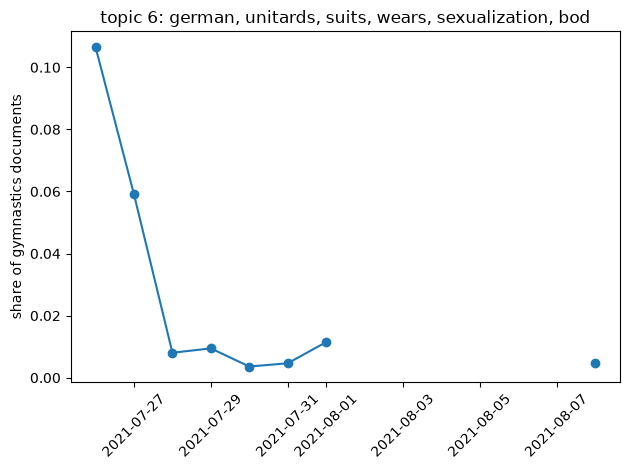

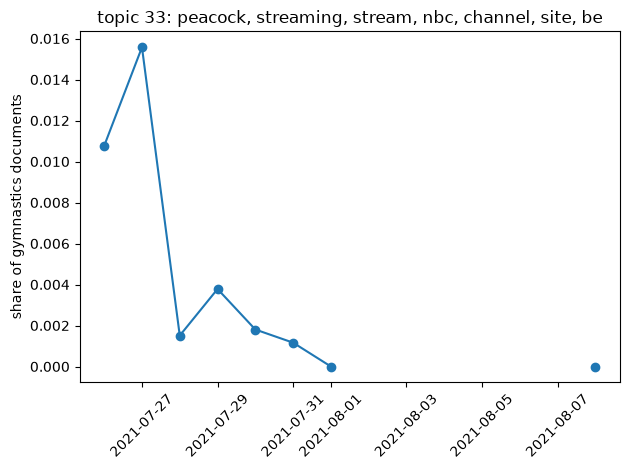

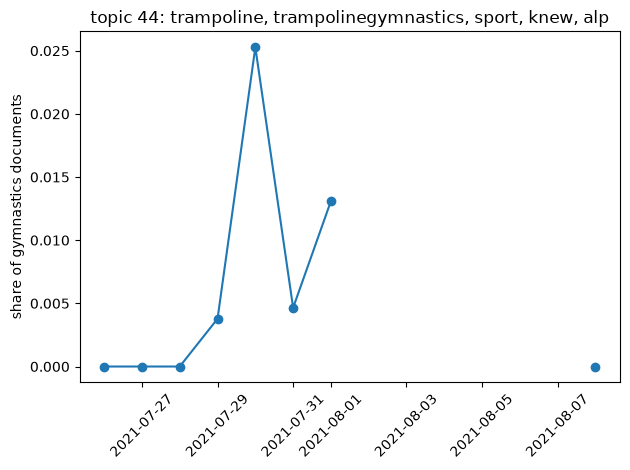

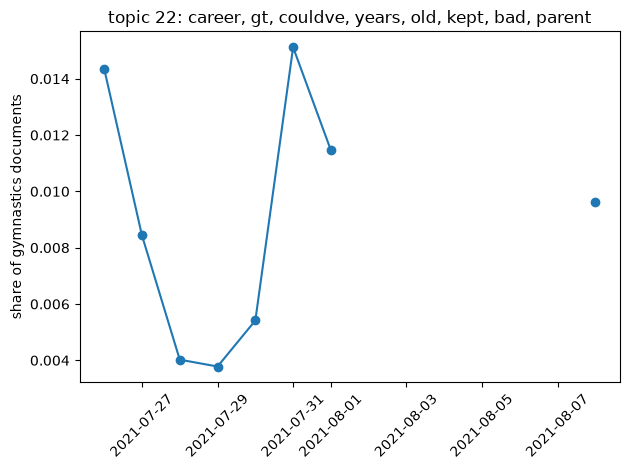

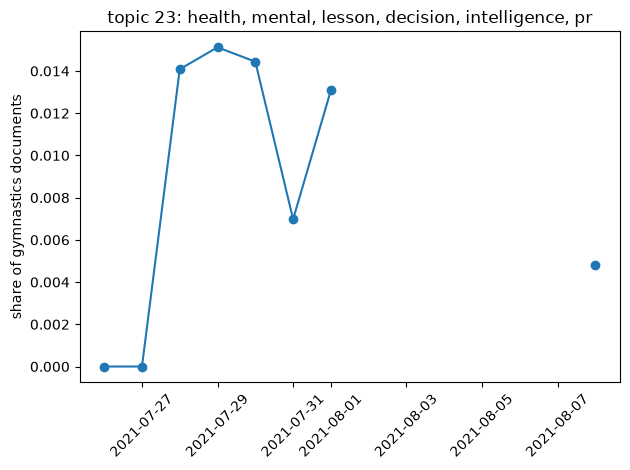

In [182]:
def prevalence(topic_id):
    values = {}
    for day in full_range:
        if day not in observed_days:
            values[day] = np.nan                
            continue
        day_tweets = gym[gym["day"] == day]
        if len(day_tweets) == 0:
            values[day] = np.nan
            continue
        if len(day_tweets) < min_documents_per_day:
            values[day] = np.nan
            continue
        values[day] = (day_tweets["topic"] == topic_id).sum() / len(day_tweets)
    return pd.Series(values)


prevalence_table = pd.DataFrame({t: prevalence(t) for t in sorted(topic_words)})
display(prevalence_table[candidates].round(4) if candidates else prevalence_table.round(4))

for t in candidates:
    s = prevalence_table[t]
    plt.plot(pd.to_datetime(list(s.index)), s.values, "o-")   # line breaks at NaN
    plt.title(f"topic {t}: {topic_words[t][:50]}")
    plt.ylabel("share of gymnastics documents")
    plt.xticks(rotation=45)
    plt.tight_layout(); plt.show()

In [183]:
def align_by_terms(reference_words, new_words, min_overlap=2):
    mapping = {}
    for ref_id, ref_terms in reference_words.items():
        ref_set = {t.strip() for t in ref_terms.split(",")}
        best, best_overlap = None, 0
        for new_id, new_terms in new_words.items():
            overlap = len(ref_set & {t.strip() for t in new_terms.split(",")})
            if overlap > best_overlap:
                best, best_overlap = new_id, overlap
        mapping[ref_id] = best if best_overlap >= min_overlap else None
    return mapping

expanding = []
for cutoff in observed_days:
    available = gym[gym["day"] <= cutoff]

    if len(available) < 300:
        expanding.append({"Cut-off": cutoff, "Documents": len(available),
                          "Topics": None, "Candidates Visible": "—"})
        continue

    um = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
              metric="cosine", random_state=seed)
    hd = HDBSCAN(min_cluster_size=min_topic_size, metric="euclidean",
                 cluster_selection_method="eom")
    m = BERTopic(embedding_model=embedder, umap_model=um, hdbscan_model=hd,
                 vectorizer_model=vectoriser, verbose=False)
    lab = np.array(m.fit_transform(available["clean"].tolist())[0])
    words_at_cutoff = {t: ", ".join(w for w, _ in m.get_topic(t)[:8])
                       for t in m.get_topic_info()["Topic"] if t != -1}

    alignment = align_by_terms({t: topic_words[t] for t in candidates},
                               words_at_cutoff)
    visible = [ref for ref, matched in alignment.items() if matched is not None]

    expanding.append({"Cut-off": cutoff, "Documents": len(available),
                      "Topics": len(words_at_cutoff),
                      "Candidates Visible": str(visible) if visible else "none"})
    print(f"   {cutoff}: {len(available):>5,} documents, "
          f"{len(words_at_cutoff):>3} topics, visible: {visible if visible else 'none'}")

    del m, lab
    gc.collect()

expanding = pd.DataFrame(expanding)
display(
    expanding.style
    .format({"Documents": "{:,.0f}", "Topics": "{:.0f}"}, na_rep="—")
    .set_properties(subset=["Candidates Visible"], **{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    .hide(axis="index")
)

print("\nFirst date each candidate becomes visible in real time")
for t in candidates:
    first_seen = None
    for _, row in expanding.iterrows():
        if isinstance(row["Candidates Visible"], str) and str(t) in row["Candidates Visible"]:
            first_seen = row["Cut-off"]
            break
    retro = prevalence_table[t].dropna()
    print(f"   topic {t}: retrospective {retro.index[0] if len(retro) else None}, "
          f"real time {first_seen if first_seen else 'never'}")

   2021-07-26:   838 documents,   3 topics, visible: [6]
   2021-07-27: 2,379 documents,   4 topics, visible: [6]
   2021-07-28: 4,367 documents,  10 topics, visible: [6, 23]
   2021-07-29: 4,896 documents,   9 topics, visible: [6, 23]
   2021-07-30: 5,450 documents,  15 topics, visible: [6, 23]
   2021-07-31: 6,310 documents,  40 topics, visible: [6, 33, 22, 23]
   2021-08-01: 6,921 documents,  45 topics, visible: [6, 33, 44, 22, 23]
   2021-08-08: 7,129 documents,  48 topics, visible: [6, 33, 44, 22, 23]


Cut-off,Documents,Topics,Candidates Visible
2021-07-25,2,—,—
2021-07-26,838,3,[6]
2021-07-27,"2,379",4,[6]
2021-07-28,"4,367",10,"[6, 23]"
2021-07-29,"4,896",9,"[6, 23]"
2021-07-30,"5,450",15,"[6, 23]"
2021-07-31,"6,310",40,"[6, 33, 22, 23]"
2021-08-01,"6,921",45,"[6, 33, 44, 22, 23]"
2021-08-08,"7,129",48,"[6, 33, 44, 22, 23]"



First date each candidate becomes visible in real time
   topic 6: retrospective 2021-07-26, real time 2021-07-26
   topic 33: retrospective 2021-07-26, real time 2021-07-31
   topic 44: retrospective 2021-07-26, real time 2021-08-01
   topic 22: retrospective 2021-07-26, real time 2021-07-31
   topic 23: retrospective 2021-07-26, real time 2021-07-28


## 10. Onset observability

In [ ]:
onset = {}
for t in sorted(topic_words):
    s = prevalence_table[t].dropna()
    if len(s) < 2:
        onset[t] = None
        continue
    threshold = s.max() * 0.25
    if s.iloc[0] >= threshold:
        onset[t] = None
    else:
        rose = s[s >= threshold]
        onset[t] = rose.index[0] if len(rose) else None

observable = [t for t in candidates if onset[t] is not None]
print("Candidates with an observable onset:", observable if observable else "None")
for t in candidates:
    print(f"   topic {t}: onset {onset[t] if onset[t] else 'Not observed'}")

Candidates with an observable onset: [44, 23]
   topic 6: onset Not observed
   topic 33: onset Not observed
   topic 44: onset 2021-07-30
   topic 22: onset Not observed
   topic 23: onset 2021-07-28


## 11. Google Trends

The query is derived by rule and **fixed before retrieval**. Values are a relative
index from 0 to 100, not search counts.

queries fixed before retrieval: {6: 'unitards', 33: 'peacock', 44: 'trampoline', 22: 'career', 23: 'lesson'}


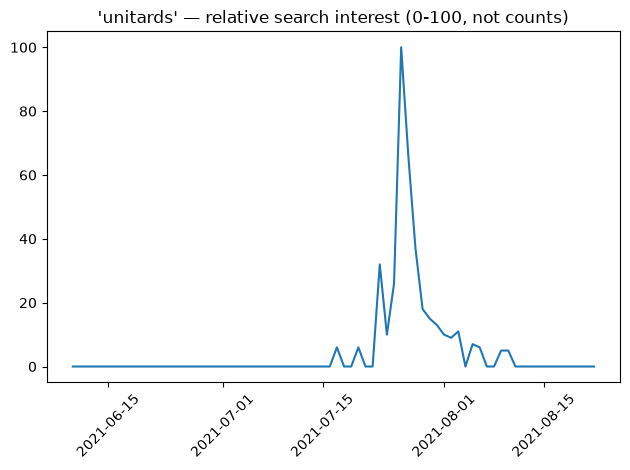

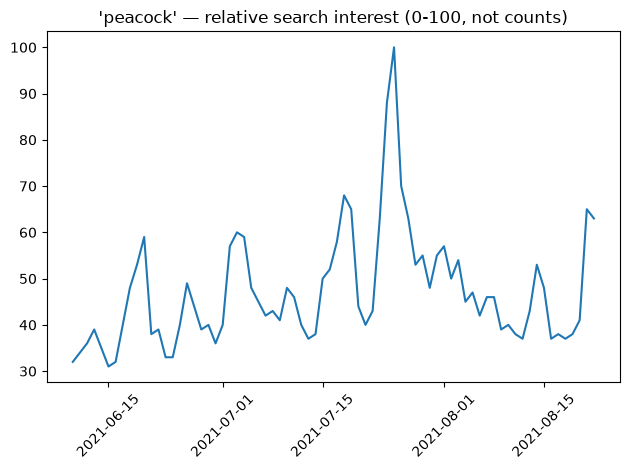

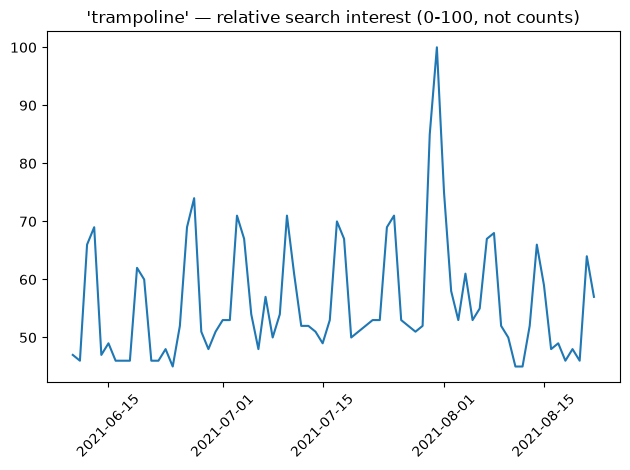

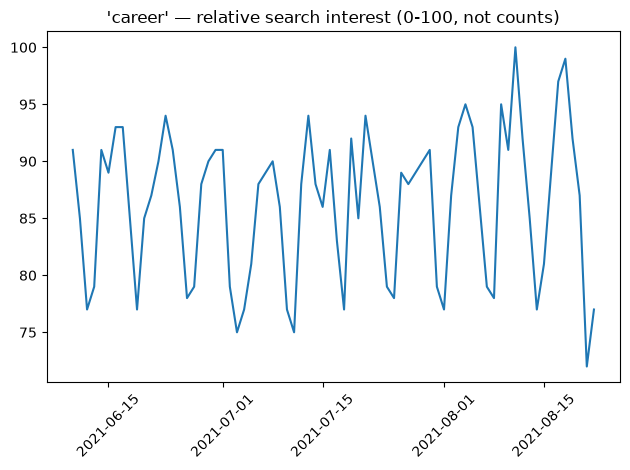

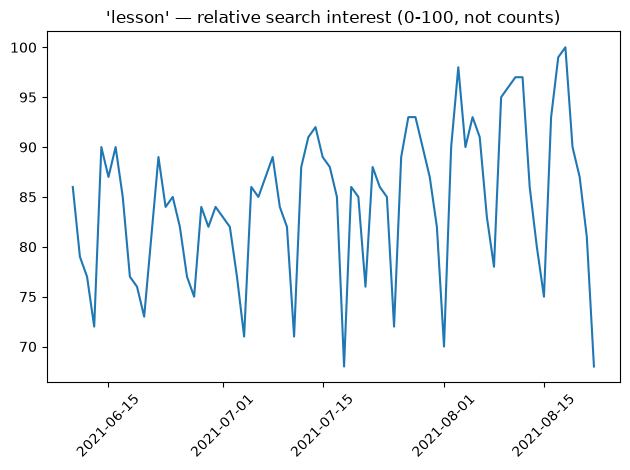

In [185]:
window_start = pd.Timestamp(min(observed_days))
trends_start = window_start - timedelta(days=45)
trends_end = pd.Timestamp(max(observed_days)) + timedelta(days=14)

too_general = {"olympic", "olympics", "tokyo", "gymnastics", "gymnast"}

queries = {}
for t in candidates:
    terms = [w.strip() for w in topic_words[t].split(",")]
    usable = [w for w in terms if len(w) >= 4 and w.lower() not in too_general]
    queries[t] = next((w for w in usable if has_exact_word(w.lower(), proxy_terms)),
                      usable[0] if usable else None)

print("queries fixed before retrieval:", queries)

excluded_queries = []

trends_data, trends_onset = {}, {}
for t, query in queries.items():
    if query is None or t in excluded_queries:
        trends_onset[t] = None
        continue

    key = hashlib.md5(f"{query}|{trends_start}|{trends_end}".encode()).hexdigest()[:12]
    cache_file = cache_folder / f"trends_{key}.csv"

    try:
        if cache_file.exists():
            s = pd.read_csv(cache_file, index_col=0, parse_dates=True).iloc[:, 0]
        else:
            conn = TrendReq(hl="en-US", tz=0)
            conn.build_payload([query],
                               timeframe=f"{trends_start.date()} {trends_end.date()}")
            result = conn.interest_over_time()
            result = result[result["isPartial"] == False]
            s = result[query].astype(float)
            s.to_frame().to_csv(cache_file)
            time.sleep(2)
    except Exception as problem:
        print(f"   '{query}' unavailable:", type(problem).__name__)
        trends_onset[t] = None
        continue

    trends_data[t] = s
    base = s[s.index < window_start]
    threshold = base.mean() + 1.5 * base.std()
    above = s[(s.index >= window_start) & (s > threshold)]
    trends_onset[t] = above.index[0].date() if len(above) else None

    plt.plot(s.index, s.values)
    plt.title(f"'{query}' — relative search interest (0-100, not counts)")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 12. Lead time

In [186]:
results = []
for t in candidates:
    twitter_onset = onset[t]
    google_onset = trends_onset.get(t)

    if twitter_onset is None:
        lead, note = None, "Twitter onset not observed"
    elif google_onset is None:
        lead, note = None, "no corresponding Trends change"
    else:
        lead = (pd.Timestamp(google_onset) - pd.Timestamp(twitter_onset)).days
        note = ("Twitter first" if lead > 0 else
                "Trends first" if lead < 0 else "same day")

    results.append({"topic": t, "query": queries.get(t),
                    "twitter onset": twitter_onset, "trends onset": google_onset,
                    "lead time (days)": lead, "interpretation": note})

results = pd.DataFrame(results)
display(results)

estimated = results[results["lead time (days)"].notna()]
print(f"\nLead time estimated for {len(estimated)} of {len(results)} candidates.")
for _, r in estimated.iterrows():
    print(f"   topic {r['topic']} ({r['query']}): "
          f"{r['lead time (days)']:+.0f} days — {r['interpretation']}")

,topic,query,twitter onset,trends onset,lead time (days),interpretation
0,6,unitards,None,2021-07-25,NaN,Twitter onset not observed
1,33,peacock,None,2021-07-25,NaN,Twitter onset not observed
2,44,trampoline,2021-07-30,2021-07-25,-5.0,Trends first
3,22,career,None,2021-08-04,NaN,Twitter onset not observed
4,23,lesson,2021-07-28,2021-07-27,-1.0,Trends first



Lead time estimated for 2 of 5 candidates.
   topic 44 (trampoline): -5 days — Trends first
   topic 23 (lesson): -1 days — Trends first
